# Notebook 1: Data Understanding, Cleaning, Feature Engineering and Exploratory Analysis
## Predicting Diabetes Risk from Everyday Health Survey Data

**Capstone research question:** Can a deep neural network, using basic health and lifestyle survey responses, accurately identify people at risk of diabetes or prediabetes, and which factors drive that risk the most?

**Why it matters (plain language):** Millions of people have diabetes or prediabetes without knowing it, and prediabetes is the stage where lifestyle changes can still prevent or delay the disease. Blood tests are the reliable way to diagnose it, but testing everyone is expensive. A tool that uses a few simple questions to decide *who to invite for screening first* could make prevention programs far more efficient.

**This notebook covers**
1. Data overview and data dictionary
2. Data quality checks (missing values, duplicates, outliers, consistency)
3. Cleaning and target definition
4. Exploratory data analysis (EDA) with visualizations
5. Descriptive and inferential statistics
6. Feature engineering
7. Train/test split and preprocessing plan

**Series (initial report):** Notebook 1 (this one) → Notebook 2 (baseline model: logistic regression). Additional models (random forest, gradient boosting, deep neural network) follow in Module 24.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42                       # fixed seed so every notebook uses the identical split
DATA_PATH = '../data/diabetes_012_health_indicators_BRFSS2015.csv'
IMG = '../images/'                      # figures used in the README are saved here
COLORS = {0: '#4C78A8', 1: '#E45756'}   # blue = not at risk, red = at risk

## 2. Data Overview

**Source:** CDC *Behavioral Risk Factor Surveillance System* (BRFSS) 2015, a large annual telephone health survey of US adults, distributed on Kaggle as the *Diabetes Health Indicators Dataset* (https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).

Each row is one survey respondent. All answers are **self-reported**, and there are **no lab values** (no blood glucose or HbA1c). This is important: it limits how accurate any model can be, and it means the model is a *screening aid*, not a diagnostic tool.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Rows: {df.shape[0]:,}   Columns: {df.shape[1]}')
df.head()

Rows: 253,680   Columns: 22


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


### Data dictionary
The column names in the file are terse, so here is a plain-language dictionary. The target is `Diabetes_012`.

In [3]:
data_dictionary = pd.DataFrame([
    ('Diabetes_012',         'TARGET: 0 = no diabetes, 1 = prediabetes, 2 = diabetes',                 'Categorical (3 classes)'),
    ('HighBP',               'Ever told by a professional that blood pressure is high',                'Binary 0/1'),
    ('HighChol',             'Ever told by a professional that cholesterol is high',                   'Binary 0/1'),
    ('CholCheck',            'Had a cholesterol check in the past 5 years',                            'Binary 0/1'),
    ('BMI',                  'Body Mass Index (weight relative to height)',                            'Numeric'),
    ('Smoker',               'Has smoked at least 100 cigarettes in lifetime',                         'Binary 0/1'),
    ('Stroke',               'Ever told had a stroke',                                                 'Binary 0/1'),
    ('HeartDiseaseorAttack', 'Coronary heart disease or heart attack',                                 'Binary 0/1'),
    ('PhysActivity',         'Physical activity in past 30 days (outside of job)',                     'Binary 0/1'),
    ('Fruits',               'Eats fruit at least once per day',                                       'Binary 0/1'),
    ('Veggies',              'Eats vegetables at least once per day',                                  'Binary 0/1'),
    ('HvyAlcoholConsump',    'Heavy drinker (men >14 drinks/week, women >7 drinks/week)',              'Binary 0/1'),
    ('AnyHealthcare',        'Has any kind of health care coverage',                                   'Binary 0/1'),
    ('NoDocbcCost',          'Needed a doctor in the past year but could not afford it',               'Binary 0/1'),
    ('GenHlth',              'Self-rated general health: 1 = excellent ... 5 = poor',                  'Ordinal 1-5'),
    ('MentHlth',             'Days of poor mental health in the past 30 days',                         'Numeric 0-30'),
    ('PhysHlth',             'Days of poor physical health in the past 30 days',                       'Numeric 0-30'),
    ('DiffWalk',             'Serious difficulty walking or climbing stairs',                          'Binary 0/1'),
    ('Sex',                  '0 = female, 1 = male',                                                   'Binary 0/1'),
    ('Age',                  '13 age bands: 1 = 18-24, 2 = 25-29, ... 12 = 75-79, 13 = 80 or older',   'Ordinal 1-13'),
    ('Education',            'Education level: 1 = never attended school ... 6 = college graduate',    'Ordinal 1-6'),
    ('Income',               'Household income: 1 = under $10k ... 8 = $75k or more',                  'Ordinal 1-8'),
], columns=['Column', 'Meaning', 'Type'])
pd.set_option('display.max_colwidth', 90)
data_dictionary

,Column,Meaning,Type
0,Diabetes_012,"TARGET: 0 = no diabetes, 1 = prediabetes, 2 = diabetes",Categorical (3 classes)
1,HighBP,Ever told by a professional that blood pressure is high,Binary 0/1
2,HighChol,Ever told by a professional that cholesterol is high,Binary 0/1
3,CholCheck,Had a cholesterol check in the past 5 years,Binary 0/1
4,BMI,Body Mass Index (weight relative to height),Numeric
5,Smoker,Has smoked at least 100 cigarettes in lifetime,Binary 0/1
6,Stroke,Ever told had a stroke,Binary 0/1
7,HeartDiseaseorAttack,Coronary heart disease or heart attack,Binary 0/1
8,PhysActivity,Physical activity in past 30 days (outside of job),Binary 0/1
9,Fruits,Eats fruit at least once per day,Binary 0/1


## 3. Data Quality Checks
Before cleaning anything, we check four things: **missing values, data types, duplicate rows, and implausible values.**

In [4]:
print('Missing values in the whole table:', int(df.isna().sum().sum()))
print('Data types:', df.dtypes.value_counts().to_dict())

# Every column is stored as float, but are they really whole numbers?
print('All values are whole numbers:', bool((df % 1 == 0).all().all()))

# Binary columns must contain only 0 and 1
binary_cols = [c for c in df.columns if df[c].nunique() == 2]
bad = [c for c in binary_cols if not set(df[c].unique()) <= {0.0, 1.0}]
print(f'{len(binary_cols)} binary columns, columns with values other than 0/1: {bad}')

Missing values in the whole table: 0
Data types: {dtype('float64'): 22}
All values are whole numbers: True


14 binary columns, columns with values other than 0/1: []


### 3a. Duplicate rows: remove or keep?
The file contains many exact duplicate rows. Our first instinct might be to delete them, but we should check *what kind* of rows they are before deciding.

In [5]:
n_dup = df.duplicated().sum()
print(f'Exact duplicate rows: {n_dup:,} ({n_dup/len(df):.1%} of the data)')

# Which classes do the duplicates belong to?
before = df['Diabetes_012'].value_counts().sort_index()
after = df.drop_duplicates()['Diabetes_012'].value_counts().sort_index()
dup_effect = pd.DataFrame({'rows_before': before, 'rows_after_dedup': after})
dup_effect['rows_removed'] = dup_effect['rows_before'] - dup_effect['rows_after_dedup']
dup_effect['pct_removed'] = (100 * dup_effect['rows_removed'] / dup_effect['rows_before']).round(1)
dup_effect.index = ['0 = no diabetes', '1 = prediabetes', '2 = diabetes']
display(dup_effect)

# Do identical answers ever have *different* outcomes? (If so, they are clearly different people.)
features_only = [c for c in df.columns if c != 'Diabetes_012']
labels_per_profile = df.assign(at_risk=(df['Diabetes_012'] > 0).astype(int)).groupby(features_only)['at_risk'].nunique()
print(f'\nIdentical answer profiles that contain BOTH at-risk and not-at-risk people: {(labels_per_profile > 1).sum():,}')

Exact duplicate rows: 23,899 (9.4% of the data)


,rows_before,rows_after_dedup,rows_removed,pct_removed
0 = no diabetes,213703,190055,23648,11.1
1 = prediabetes,4631,4629,2,0.0
2 = diabetes,35346,35097,249,0.7



Identical answer profiles that contain BOTH at-risk and not-at-risk people: 1,804


**Decision: keep the duplicates.**

- The survey has 21 mostly yes/no questions answered by ~250,000 people, so many *different* people will give identical answers purely by chance. Nothing here suggests data-entry errors.
- Removing them is **not neutral**: almost all the removed rows are healthy respondents with very common answer patterns (about 11% of class 0 but under 1% of class 2). Deleting them would artificially inflate the share of at-risk people and make the sample less representative of the real population.
- Identical profiles with different outcomes prove they represent different individuals.

In Notebook 2 we run a **sensitivity check** (re-training the baseline with duplicates removed) to confirm this choice does not change our conclusions.

### 3b. Outliers
`BMI` is the only truly continuous feature with questionable values. Let's look at its extremes.

count    253680.0
mean         28.4
std           6.6
min          12.0
25%          24.0
50%          27.0
75%          31.0
max          98.0

Respondents with BMI > 50: 2,175
Respondents with BMI > 60: 805
Respondents with BMI > 70: 584
Respondents with BMI < 15: 68


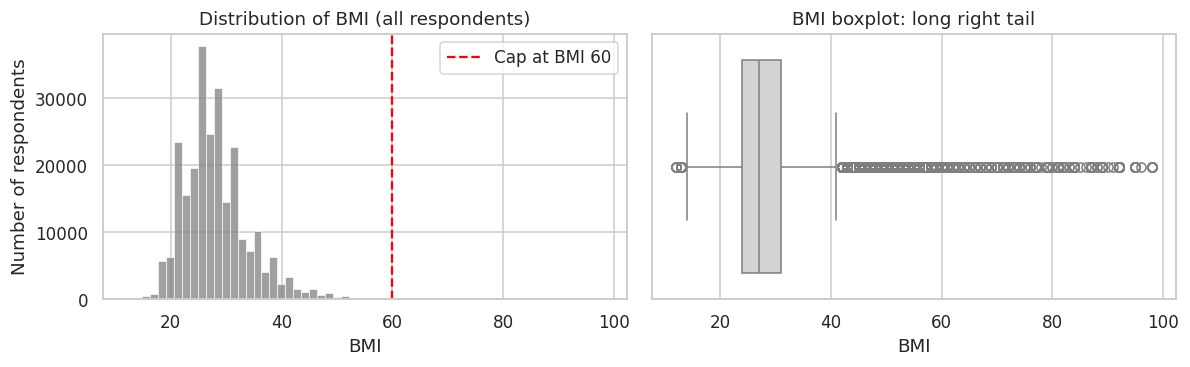

In [6]:
print(df['BMI'].describe().round(1).to_string())
print()
for cutoff in (50, 60, 70):
    print(f'Respondents with BMI > {cutoff}: {(df.BMI > cutoff).sum():,}')
print(f'Respondents with BMI < 15: {(df.BMI < 15).sum():,}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df['BMI'], bins=60, color='gray', ax=ax[0])
ax[0].axvline(60, color='red', ls='--', label='Cap at BMI 60')
ax[0].set(title='Distribution of BMI (all respondents)', xlabel='BMI', ylabel='Number of respondents')
ax[0].legend()
sns.boxplot(x=df['BMI'], color='lightgray', ax=ax[1])
ax[1].set(title='BMI boxplot: long right tail', xlabel='BMI')
plt.tight_layout(); plt.show()

BMI is strongly right-skewed. Values above ~60 are extremely rare and some (up to 98) are likely reporting errors. Rather than deleting respondents (and their other, valid answers), we **cap BMI at 60** (winsorizing). This protects the neural network and logistic regression from extreme values while keeping every row. Tree-based models are unaffected either way.

## 4. Cleaning and Target Definition
Steps applied:
1. **Binary target.** We merge *prediabetes* (1) and *diabetes* (2) into a single **`at_risk`** label (1 = prediabetes or diabetes, 0 = neither). Reasons: (a) our goal is *screening*, so anyone in classes 1 or 2 should be invited for a blood test; (b) prediabetes is only 1.8% of the data and, as shown below, is too rare to learn reliably as a separate class.
2. **Cap BMI at 60.**
3. **Convert columns to integers** (they are whole numbers stored as floats).
4. **Keep all rows** (no missing values, duplicates retained as justified above).

In [7]:
n_capped = int((df['BMI'] > 60).sum())

df['at_risk'] = (df['Diabetes_012'] > 0).astype(int)   # 1 = prediabetes or diabetes
df['BMI'] = df['BMI'].clip(upper=60)                    # winsorize extreme BMI values
df = df.astype(int)                                      # whole numbers stored as floats -> ints

print(f'BMI values capped: {n_capped:,} respondents')
print(f'Final shape: {df.shape}')
print('\nClass balance (binary target):')
print(df['at_risk'].value_counts().rename({0: 'Not at risk', 1: 'At risk'}).to_frame('count').assign(share=lambda t: (t['count']/len(df)).round(3)))

BMI values capped: 805 respondents
Final shape: (253680, 23)

Class balance (binary target):
              count  share
at_risk                   
Not at risk  213703  0.842
At risk       39977  0.158


## 5. Exploratory Data Analysis (EDA)
To make plots readable, we make a **labelled copy** of the data (`eda`) where the numeric codes are replaced by human-readable categories. The modeling data (`df`) stays numeric.

In [8]:
age_labels = {1:'18-24', 2:'25-29', 3:'30-34', 4:'35-39', 5:'40-44', 6:'45-49', 7:'50-54',
              8:'55-59', 9:'60-64', 10:'65-69', 11:'70-74', 12:'75-79', 13:'80+'}
income_labels = {1:'<$10k', 2:'$10-15k', 3:'$15-20k', 4:'$20-25k', 5:'$25-35k', 6:'$35-50k', 7:'$50-75k', 8:'$75k+'}
education_labels = {1:'None/Kinder', 2:'Elementary', 3:'Some HS', 4:'HS grad', 5:'Some college', 6:'College grad'}
genhlth_labels = {1:'Excellent', 2:'Very good', 3:'Good', 4:'Fair', 5:'Poor'}

eda = df.copy()
eda['Status'] = eda['Diabetes_012'].map({0: 'No diabetes', 1: 'Prediabetes', 2: 'Diabetes'})
eda['Risk group'] = eda['at_risk'].map({0: 'Not at risk', 1: 'At risk'})

overall_rate = df['at_risk'].mean() * 100
print(f'Overall share of respondents at risk (prediabetes or diabetes): {overall_rate:.1f}%')

Overall share of respondents at risk (prediabetes or diabetes): 15.8%


### 5a. The target: how imbalanced is it?

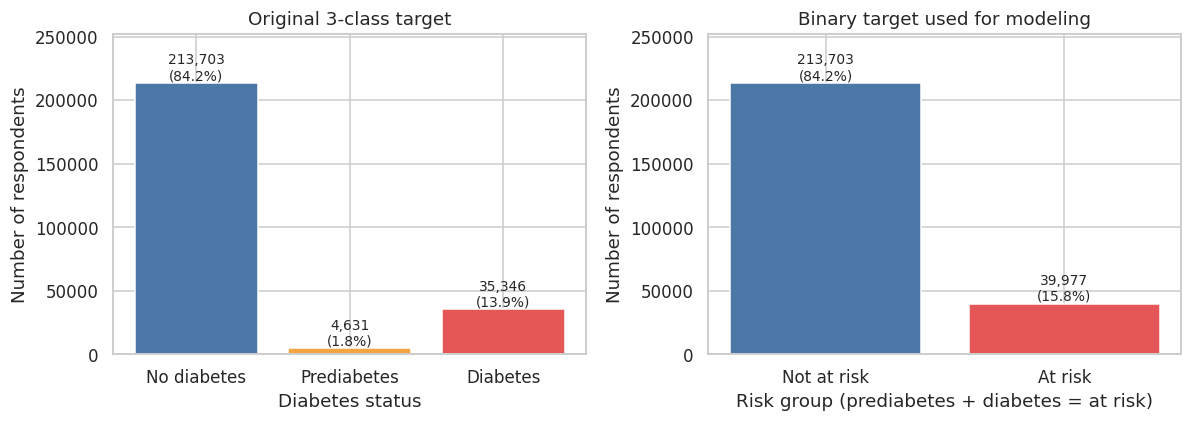

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts3 = eda['Status'].value_counts().reindex(['No diabetes', 'Prediabetes', 'Diabetes'])
bars = ax[0].bar(counts3.index, counts3.values, color=['#4C78A8', '#F2A541', '#E45756'])
for b, v in zip(bars, counts3.values):
    ax[0].text(b.get_x() + b.get_width()/2, v, f'{v:,}\n({v/len(eda):.1%})', ha='center', va='bottom', fontsize=9)
ax[0].set(title='Original 3-class target', xlabel='Diabetes status', ylabel='Number of respondents', ylim=(0, counts3.max()*1.18))

counts2 = eda['Risk group'].value_counts().reindex(['Not at risk', 'At risk'])
bars = ax[1].bar(counts2.index, counts2.values, color=[COLORS[0], COLORS[1]])
for b, v in zip(bars, counts2.values):
    ax[1].text(b.get_x() + b.get_width()/2, v, f'{v:,}\n({v/len(eda):.1%})', ha='center', va='bottom', fontsize=9)
ax[1].set(title='Binary target used for modeling', xlabel='Risk group (prediabetes + diabetes = at risk)', ylabel='Number of respondents', ylim=(0, counts2.max()*1.18))
plt.tight_layout()
plt.savefig(IMG + 'eda_target_distribution.png', bbox_inches='tight'); plt.show()

**What this means:** only about 1 in 6 respondents is at risk. A lazy model that says *"nobody is at risk"* would be right about 84% of the time while being useless for screening. That is why **accuracy is a poor metric here**, and why we will rely on ROC-AUC, PR-AUC, recall and precision instead (explained in Notebook 2).

### 5b. Continuous features: BMI and days of poor health

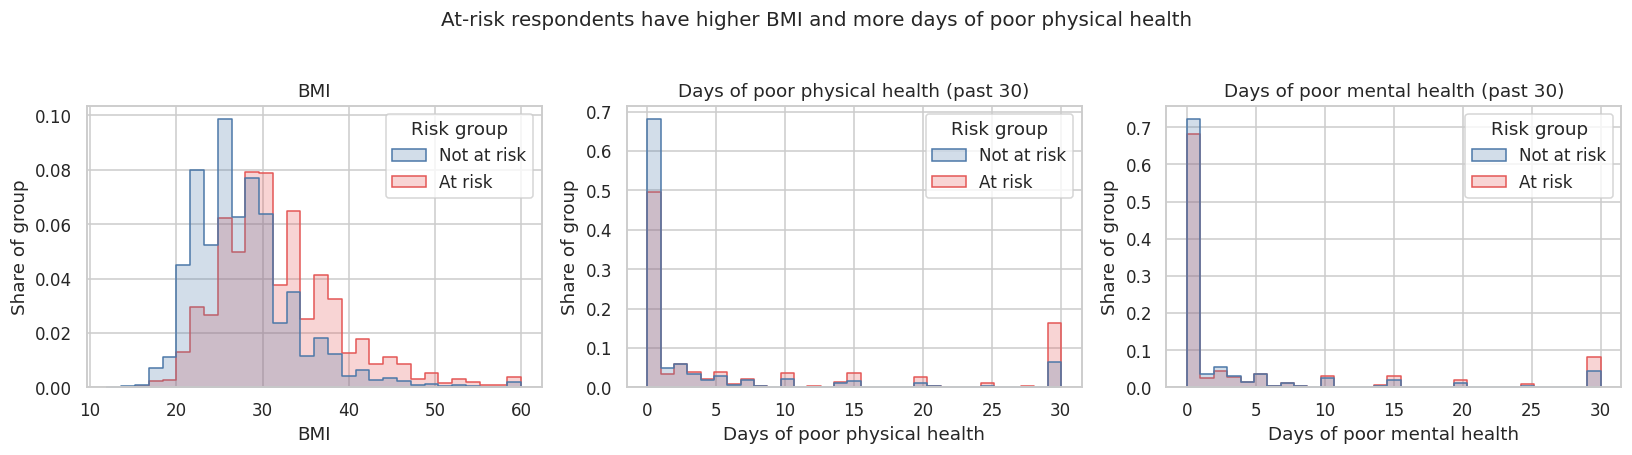

              BMI        PhysHlth        MentHlth       
             mean median     mean median     mean median
Risk group                                              
At risk      31.7   31.0      7.8    1.0      4.5    0.0
Not at risk  27.7   27.0      3.6    0.0      2.9    0.0


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, title in zip(ax, ['BMI', 'PhysHlth', 'MentHlth'],
                         ['BMI', 'Days of poor physical health (past 30)', 'Days of poor mental health (past 30)']):
    sns.histplot(data=eda, x=col, hue='Risk group', hue_order=['Not at risk', 'At risk'],
                 palette=[COLORS[0], COLORS[1]], stat='density', common_norm=False,
                 element='step', bins=30 if col == 'BMI' else 31, ax=a)
    a.set(title=title, xlabel=title.split(' (')[0], ylabel='Share of group')
plt.suptitle('At-risk respondents have higher BMI and more days of poor physical health', y=1.03, fontsize=13)
plt.tight_layout()
plt.savefig(IMG + 'eda_continuous_features.png', bbox_inches='tight'); plt.show()

print(eda.groupby('Risk group')[['BMI', 'PhysHlth', 'MentHlth']].agg(['mean', 'median']).round(1))

- **BMI:** the at-risk group is shifted to the right (higher BMI).
- **Physical health days:** most people report 0 days of poor health (the large spike at 0), but the at-risk group has many more people at the high end (up to 30 days).
- **Mental health days:** the two groups look much more alike (median of 0 days for both; average 4.5 vs. 2.9 days). We expect this feature to matter much less.

### 5c. Risk by age, general health, income and education

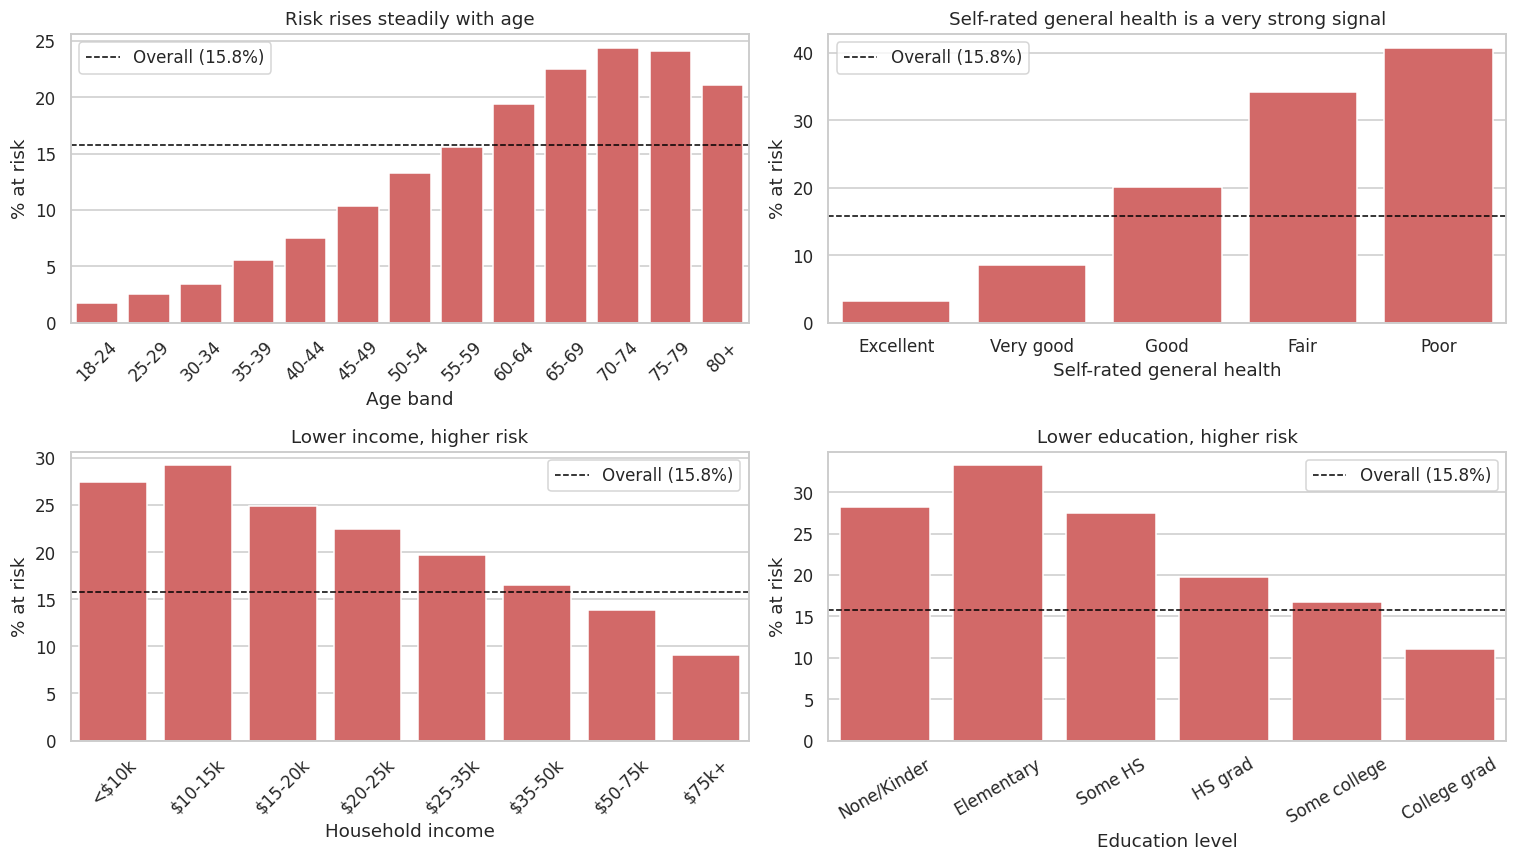

In [11]:
def rate_by(col, labels, ax, title, xlabel, rotate=0):
    t = eda.groupby(col)['at_risk'].mean().mul(100)
    t.index = [labels[i] for i in t.index]
    sns.barplot(x=t.index, y=t.values, color='#E45756', ax=ax)
    ax.axhline(overall_rate, color='black', ls='--', lw=1, label=f'Overall ({overall_rate:.1f}%)')
    ax.set(title=title, xlabel=xlabel, ylabel='% at risk')
    ax.tick_params(axis='x', rotation=rotate)
    ax.legend()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
rate_by('Age', age_labels, axes[0, 0], 'Risk rises steadily with age', 'Age band', rotate=45)
rate_by('GenHlth', genhlth_labels, axes[0, 1], 'Self-rated general health is a very strong signal', 'Self-rated general health')
rate_by('Income', income_labels, axes[1, 0], 'Lower income, higher risk', 'Household income', rotate=45)
rate_by('Education', education_labels, axes[1, 1], 'Lower education, higher risk', 'Education level', rotate=30)
plt.tight_layout()
plt.savefig(IMG + 'eda_risk_by_group.png', bbox_inches='tight'); plt.show()

All four show a clear, **broadly steady gradient**: risk climbs with age (levelling off after about 70), climbs sharply as self-rated health worsens (from about 3% for "Excellent" to about 40% for "Poor"), and falls as income and education rise. There are small exceptions (the very lowest income and education bands are not the very highest-risk ones), but the overall trend is ordered. That means we can keep these variables as ordered numbers (no one-hot encoding needed) and the models can learn simple "more of this, more risk" patterns. 

Income and education are *socioeconomic markers*, not causes. They are likely linked to access to healthy food, healthcare and time for exercise.

### 5d. Yes/No risk factors: how much does each one change the odds of being at risk?

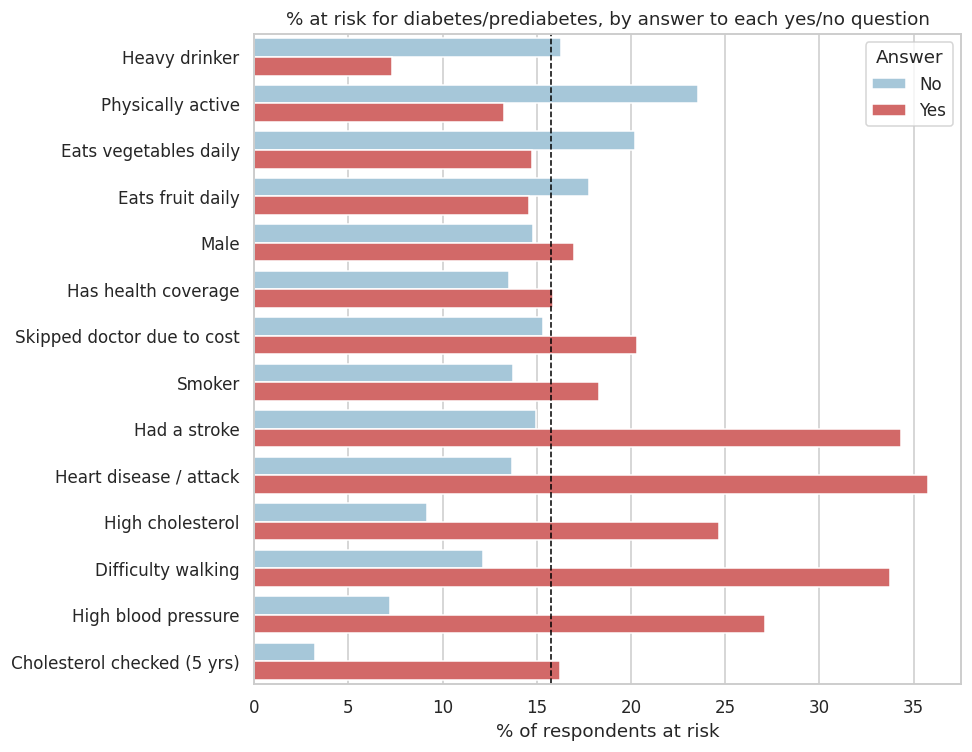

In [12]:
binary_features = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
                   'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare',
                   'NoDocbcCost', 'DiffWalk', 'Sex']
pretty = {'HighBP': 'High blood pressure', 'HighChol': 'High cholesterol', 'CholCheck': 'Cholesterol checked (5 yrs)',
          'Smoker': 'Smoker', 'Stroke': 'Had a stroke', 'HeartDiseaseorAttack': 'Heart disease / attack',
          'PhysActivity': 'Physically active', 'Fruits': 'Eats fruit daily', 'Veggies': 'Eats vegetables daily',
          'HvyAlcoholConsump': 'Heavy drinker', 'AnyHealthcare': 'Has health coverage',
          'NoDocbcCost': 'Skipped doctor due to cost', 'DiffWalk': 'Difficulty walking', 'Sex': 'Male'}

rows = []
for c in binary_features:
    r_yes = df.loc[df[c] == 1, 'at_risk'].mean() * 100
    r_no = df.loc[df[c] == 0, 'at_risk'].mean() * 100
    rows.append((pretty[c], r_no, r_yes))
rates = pd.DataFrame(rows, columns=['Feature', 'No', 'Yes'])
rates['ratio'] = rates['Yes'] / rates['No']
rates = rates.sort_values('ratio')

long = rates.melt(id_vars=['Feature', 'ratio'], value_vars=['No', 'Yes'], var_name='Answer', value_name='pct')
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=long, y='Feature', x='pct', hue='Answer', order=rates['Feature'],
            palette={'No': '#9ecae1', 'Yes': '#E45756'}, ax=ax)
ax.axvline(overall_rate, color='black', ls='--', lw=1)
ax.set(title='% at risk for diabetes/prediabetes, by answer to each yes/no question',
       xlabel='% of respondents at risk', ylabel='')
plt.tight_layout()
plt.savefig(IMG + 'eda_binary_risk_factors.png', bbox_inches='tight'); plt.show()

**What stands out**

- The biggest jumps are for **high blood pressure** (about 27% at risk vs. 7% without), **high cholesterol**, **difficulty walking**, **heart disease** and **stroke**. These conditions commonly occur together with diabetes.
- Being **physically active** and eating **vegetables/fruit daily** are associated with lower risk.
- Three results look backwards and are worth explaining honestly rather than taking at face value:
  - **Heavy drinkers show *lower* risk.** This is very likely *not* protective. People already diagnosed are often advised to avoid alcohol, and heavy drinking is rare in older, sicker groups (so-called reverse causality / "healthy-user" effects).
  - **Having had a cholesterol check, or having health coverage, shows *higher* risk.** This is a *detection effect*: people who see doctors are more likely to have been *diagnosed*, and diagnosis is what the survey records. People with undiagnosed diabetes who avoid the doctor are counted as "not at risk" in this data.

The last point is a real limitation: **the labels reflect diagnosed conditions, not true disease status.** We return to this in the conclusions.

### 5e. Correlations

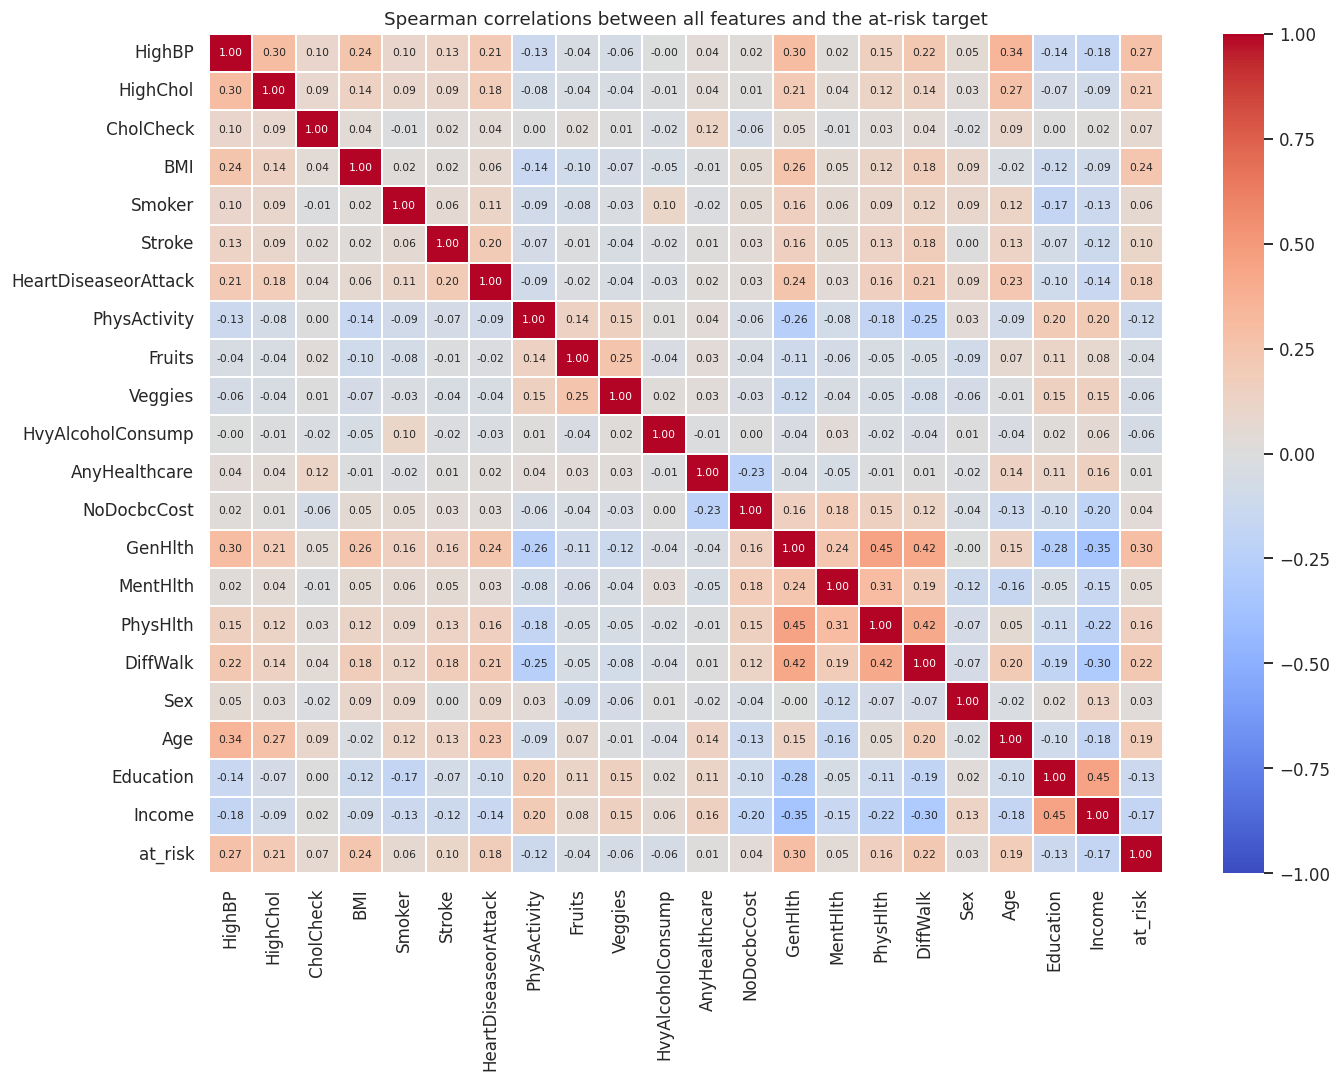

Strongest correlations with being at risk:
GenHlth                 0.296
HighBP                  0.270
BMI                     0.235
DiffWalk                0.222
HighChol                0.210
Age                     0.186
HeartDiseaseorAttack    0.177
Income                 -0.172

Largest correlation between two *features*: 0.45


In [13]:
# Spearman correlation is appropriate because many variables are binary or ordinal
corr = df.drop(columns=['Diabetes_012']).corr(method='spearman')
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='coolwarm', center=0,
            vmin=-1, vmax=1, linewidths=.3, ax=ax)
ax.set_title('Spearman correlations between all features and the at-risk target')
plt.tight_layout()
plt.savefig(IMG + 'eda_correlation_heatmap.png', bbox_inches='tight'); plt.show()

target_corr = corr['at_risk'].drop('at_risk').sort_values(key=abs, ascending=False)
print('Strongest correlations with being at risk:')
print(target_corr.head(8).round(3).to_string())
print(f'\nLargest correlation between two *features*: {corr.drop(index="at_risk", columns="at_risk").where(~np.eye(len(corr)-1, dtype=bool)).abs().max().max():.2f}')

No single feature is strongly correlated with the target (the strongest, general health, is only about 0.30), so **no one question is enough**. The signal is spread across many features, which is the kind of problem where combining features in a model helps. The largest correlation between two *features* is about 0.45 (the physical-health, general-health and difficulty-walking group of questions), so multicollinearity is not a serious concern for modeling.

## 6. Statistical Tests
EDA suggests which features differ between groups; here we test whether those differences are **statistically significant** and, more importantly, **how large** they are.

- **Binary features:** chi-square test of independence, with the **odds ratio** (how many times higher the odds of being at risk are for "yes" vs "no") and **Cramér's V** (effect size from 0 = no association to 1 = perfect association).
- **Numeric/ordinal features:** Mann-Whitney U test (no normality assumption) with **rank-biserial correlation** as the effect size.

> **Caution:** with ~250,000 rows, almost *any* difference will have p < 0.05. So the p-value only tells us a difference is unlikely to be chance; the **effect size** tells us whether it matters.

In [14]:
# --- Binary features: chi-square + odds ratio + Cramer's V ---
chi_rows = []
for c in binary_features:
    ct = pd.crosstab(df[c], df['at_risk'])
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    a, b = ct.loc[1, 1], ct.loc[1, 0]      # at risk / not at risk among "yes"
    c0, d = ct.loc[0, 1], ct.loc[0, 0]     # at risk / not at risk among "no"
    odds_ratio = (a / b) / (c0 / d)
    cramers_v = np.sqrt(chi2 / len(df))
    chi_rows.append((pretty[c], odds_ratio, cramers_v, p))
chi_table = pd.DataFrame(chi_rows, columns=['Feature', 'Odds ratio', "Cramer's V", 'p-value']).sort_values("Cramer's V", ascending=False)
chi_table['p-value'] = chi_table['p-value'].apply(lambda p: '<0.001' if p < 0.001 else f'{p:.3f}')
display(chi_table.round(3).reset_index(drop=True))

,Feature,Odds ratio,Cramer's V,p-value
0,High blood pressure,4.782,0.270,<0.001
1,Difficulty walking,3.696,0.222,<0.001
2,High cholesterol,3.242,0.210,<0.001
3,Heart disease / attack,3.511,0.177,<0.001
4,Physically active,0.496,0.121,<0.001
5,Had a stroke,2.968,0.105,<0.001
6,Cholesterol checked (5 yrs),5.868,0.068,<0.001
7,Smoker,1.411,0.063,<0.001
8,Eats vegetables daily,0.680,0.059,<0.001
9,Heavy drinker,0.405,0.057,<0.001


In [15]:
# --- Numeric / ordinal features: Mann-Whitney U + rank-biserial effect size ---
num_feats = ['BMI', 'Age', 'GenHlth', 'PhysHlth', 'MentHlth', 'Income', 'Education']
mw_rows = []
for c in num_feats:
    g1 = df.loc[df['at_risk'] == 1, c]; g0 = df.loc[df['at_risk'] == 0, c]
    u, p = stats.mannwhitneyu(g1, g0, alternative='two-sided')
    rbc = 2 * u / (len(g1) * len(g0)) - 1          # >0: at-risk tend to have HIGHER values
    mw_rows.append((c, g0.median(), g1.median(), rbc, p))
mw_table = pd.DataFrame(mw_rows, columns=['Feature', 'Median (not at risk)', 'Median (at risk)', 'Rank-biserial r', 'p-value'])
mw_table['p-value'] = mw_table['p-value'].apply(lambda p: '<0.001' if p < 0.001 else f'{p:.3f}')
display(mw_table.sort_values('Rank-biserial r', key=abs, ascending=False).round(3).reset_index(drop=True))

,Feature,Median (not at risk),Median (at risk),Rank-biserial r,p-value
0,GenHlth,2.0,3.0,0.450,<0.001
1,BMI,27.0,31.0,0.372,<0.001
2,Age,8.0,10.0,0.293,<0.001
3,Income,7.0,6.0,-0.266,<0.001
4,PhysHlth,0.0,1.0,0.221,<0.001
5,Education,5.0,5.0,-0.189,<0.001
6,MentHlth,0.0,0.0,0.059,<0.001


**Reading the tables**

- Nearly everything is statistically significant (as expected with this sample size), so we focus on effect sizes.
- **Largest associations:** general health rating, high blood pressure, difficulty walking, BMI, age, high cholesterol and heart disease. These are the factors we expect the models to rely on most.
- **Weak or tiny associations:** sex, fruit intake, having health coverage, and (for the numeric variables) mental health days. They are statistically detectable but have tiny effect sizes, so they will contribute little.
- Odds ratios above 1 mean *higher* odds of being at risk; below 1 means *protective* (e.g., being physically active).

These are **associations, not causes**. For instance, people with diabetes may become *less* active because of symptoms, not only the other way around.

## 7. Feature Engineering
The raw features are already numeric, but EDA suggested patterns a simple linear model might miss. We create four new features, each motivated by something seen above:

| New feature | How it is built | Why |
|---|---|---|
| `BMI_category` | WHO bands: underweight (<18.5), normal (18.5-25), overweight (25-30), obese I (30-35), obese II (35-40), obese III (40+) | Risk may jump at obesity thresholds rather than rise in a straight line with BMI |
| `n_conditions` | Count of high blood pressure, high cholesterol, heart disease, stroke (0-4) | These conditions cluster together; the *number* a person has may matter more than each one alone |
| `lifestyle_score` | Physically active + eats fruit + eats vegetables + non-smoker (0-4) | Summarizes healthy habits whose individual effects are small |
| `age_x_bmi` | Age band × BMI | High BMI may matter more at older ages (an *interaction* a linear model cannot learn on its own) |

Whether these features actually improve prediction is tested in Notebook 2, by comparing the baseline model with and without them.

In [16]:
# 1. WHO BMI bands (BMI is already capped at 60, so the last band is [40, 61))
bmi_names = ['Underweight', 'Normal', 'Overweight', 'Obese I', 'Obese II', 'Obese III']
df['BMI_category'] = pd.cut(df['BMI'], bins=[0, 18.5, 25, 30, 35, 40, 61], labels=False, right=False).astype(int)

# 2. Number of cardiometabolic conditions (0-4)
df['n_conditions'] = df[['HighBP', 'HighChol', 'HeartDiseaseorAttack', 'Stroke']].sum(axis=1)

# 3. Healthy-lifestyle score (0-4): active, fruit, vegetables, non-smoker
df['lifestyle_score'] = df['PhysActivity'] + df['Fruits'] + df['Veggies'] + (1 - df['Smoker'])

# 4. Interaction between age band and BMI
df['age_x_bmi'] = df['Age'] * df['BMI']

engineered = ['BMI_category', 'n_conditions', 'lifestyle_score', 'age_x_bmi']
df[engineered].describe().round(2)

,BMI_category,n_conditions,lifestyle_score,age_x_bmi
count,253680.00,253680.00,253680.00,253680.00
mean,2.24,0.99,2.76,226.89
std,1.13,0.97,1.05,96.87
min,0.00,0.00,0.00,14.00
25%,1.00,0.00,2.00,161.00
50%,2.00,1.00,3.00,230.00
75%,3.00,2.00,4.00,290.00
max,5.00,4.00,4.00,780.00


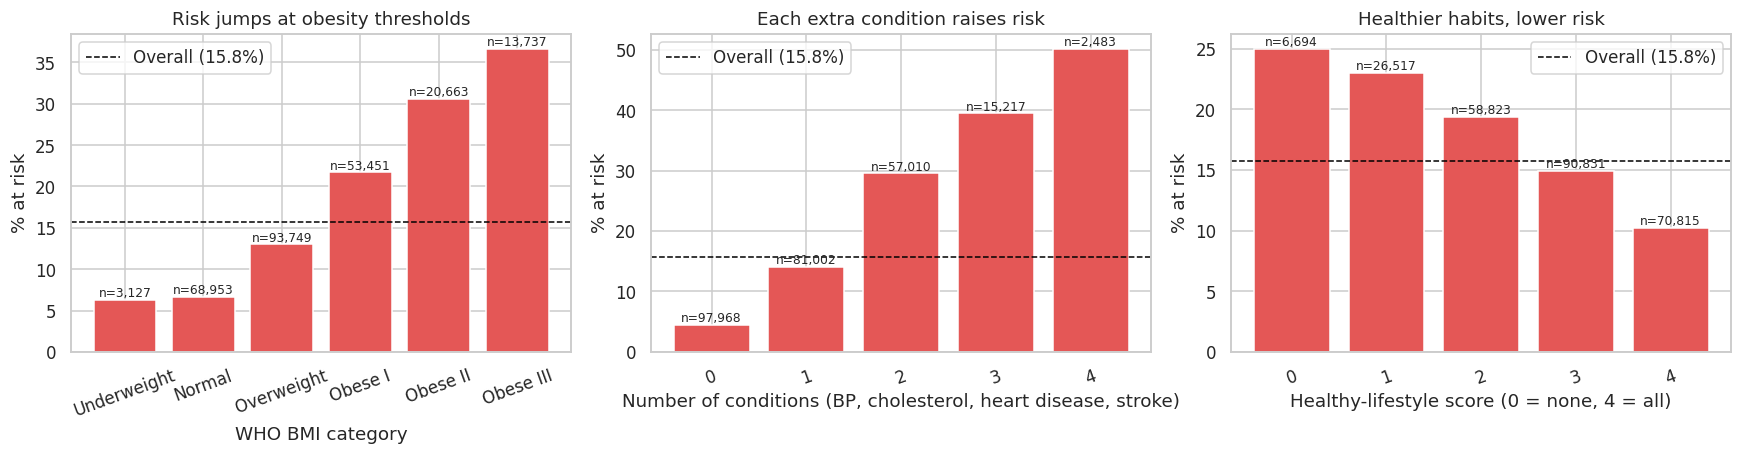

Spearman correlation with the at-risk target (engineered vs. the original features they come from):
n_conditions       0.313
age_x_bmi          0.293
HighBP             0.270
BMI                0.235
BMI_category       0.228
Age                0.186
lifestyle_score   -0.121


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
plot_specs = [('BMI_category', dict(enumerate(bmi_names)), 'Risk jumps at obesity thresholds', 'WHO BMI category'),
              ('n_conditions', {i: str(i) for i in range(5)}, 'Each extra condition raises risk', 'Number of conditions (BP, cholesterol, heart disease, stroke)'),
              ('lifestyle_score', {i: str(i) for i in range(5)}, 'Healthier habits, lower risk', 'Healthy-lifestyle score (0 = none, 4 = all)')]
for ax, (col, labels, title, xlabel) in zip(axes, plot_specs):
    t = df.groupby(col)['at_risk'].agg(['mean', 'size'])
    bars = ax.bar([labels[i] for i in t.index], t['mean'] * 100, color='#E45756')
    for b, n in zip(bars, t['size']):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'n={n:,}', ha='center', va='bottom', fontsize=8)
    ax.axhline(overall_rate, color='black', ls='--', lw=1, label=f'Overall ({overall_rate:.1f}%)')
    ax.set(title=title, xlabel=xlabel, ylabel='% at risk')
    ax.tick_params(axis='x', rotation=20)
    ax.legend()
plt.tight_layout()
plt.savefig(IMG + 'fe_engineered_features.png', bbox_inches='tight'); plt.show()

fe_corr = df[engineered + ['BMI', 'HighBP', 'Age']].corrwith(df['at_risk'], method='spearman').round(3)
print('Spearman correlation with the at-risk target (engineered vs. the original features they come from):')
print(fe_corr.sort_values(ascending=False).to_string())

**What the engineered features show**

- **BMI category:** risk is flat from underweight to normal weight (about 6-7%), then climbs at every band: about 13% for overweight, 22% for obese I, 30% for obese II and 37% for obese III. The jump is steeper than a straight line in BMI suggests, which is the pattern one-hot bands let a linear model capture.
- **Number of conditions:** a very steep staircase, from about 4% with none to about 30% with two and about 50% with all four. With a correlation of 0.31, it is **more strongly related to risk than any single original feature** (the best original, general health, is 0.30; high blood pressure alone is 0.27).
- **Age × BMI:** correlation 0.29, higher than age (0.19) or BMI (0.24) on their own, supporting the idea that the two reinforce each other.
- **Lifestyle score:** a clear gradient (about 25% at risk with no healthy habits vs. about 10% with all four), though weaker (correlation -0.12) than the medical features.

Correlation with the target does not guarantee better *prediction*, because these features re-use information already in the originals. Notebook 2 tests whether they actually help the baseline model.

## 8. Train/Test Split and Preprocessing Plan

**Split:** 80% training / 20% test, **stratified** on the target so both parts keep the same ~16% at-risk share. The test set is set aside now and used **only once**, at the very end of Notebook 2, so our final scores are an honest estimate of performance on new people. All tuning uses cross-validation *inside* the training set.

**Encoding:** binary features are already 0/1 and the ordinal features (age band, income, education, general health) show ordered trends, so they are kept as numbers. The one exception is the engineered `BMI_category`: it is **one-hot encoded** in Notebook 2 so the model can give each BMI band its own effect.

**Scaling:** logistic regression (and the neural network planned for Module 24) is sensitive to feature scale, so we apply `StandardScaler`. It is placed **inside the modeling pipeline** and fitted on training folds only, to avoid *data leakage* from the validation/test data. Tree-based models do not need scaling.

**Class imbalance:** handled with **class weights** (errors on the rare at-risk class are penalized more heavily), not by synthetic oversampling. This keeps the test data realistic and avoids duplicating information.

In [18]:
X = df.drop(columns=['Diabetes_012', 'at_risk'])   # 21 original + 4 engineered features (3-class label dropped to prevent leakage)
y = df['at_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

summary = pd.DataFrame({
    'Rows': [len(X_train), len(X_test)],
    'At-risk rows': [int(y_train.sum()), int(y_test.sum())],
    'At-risk share': [f'{y_train.mean():.1%}', f'{y_test.mean():.1%}'],
}, index=['Training set', 'Test set'])
display(summary)
print('Features used for modeling:', list(X.columns))

,Rows,At-risk rows,At-risk share
Training set,202944,31982,15.8%
Test set,50736,7995,15.8%


Features used for modeling: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'BMI_category', 'n_conditions', 'lifestyle_score', 'age_x_bmi']


## 9. Summary of Findings from Exploration

1. **Data quality is good:** no missing values, all binary columns valid. We kept duplicates (different people with identical answers), capped extreme BMI values at 60 and defined a binary *at-risk* target.
2. **The classes are imbalanced** (~16% at risk), so accuracy is misleading and class weighting plus the right metrics are required.
3. **Clear risk gradients exist:** risk rises with age, BMI, worse self-rated health, high blood pressure, high cholesterol, heart disease and difficulty walking, and falls with higher income, education and physical activity.
4. **No single feature is decisive** (all correlations with the target are modest), which motivates combining features in a predictive model.
5. **All data comes from self-reports** with no lab values, which will limit achievable accuracy.

6. **Feature engineering** produced four candidate features. The count of cardiometabolic conditions and the age × BMI interaction are more strongly related to risk than any single original feature.

**Next:** Notebook 2 builds the baseline model (logistic regression) with and without the engineered features.